# XAUUSD — simulated end-2024 d review (0.25 → 0.30)

Simulates the yearly review on **2024-12-31** for gold, using only data available that day.

| Step | What happens |
|---|---|
| 1. Health check | FFD at d = 0.25 (τ = 1e-4) fails ADF on 2024 and 2023–24 → persistent failure (maintenance rule, README §3) |
| 2. Re-select d | Same rule as the original selection: smallest d with ADF p < 0.01, grid 0.20–0.60 in steps of 0.05, τ fixed at 1e-4, on the **last 3 years (2022-01-01 → 2024-12-31)** |
| 3. Apply | Recompute gold's **whole FFD history** with the new d (no stitching of old-d and new-d values). New FFD window → new rolling-Z window (= FFD window) and a new Z anchor |
| 4. Forward check | 2025 is out of sample for the new d: look, don't re-tune |

Method unchanged: fixed-width window FFD on `log(close)`, daily. ADF: `regression='c', maxlag=1, autolag=None`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import adfuller

DATA = Path('../../data')
SYM = 'XAUUSD'
TAU, D_OLD = 1e-4, 0.25
REVIEW = '2024-12-31'
SELECT = ('2022-01-01', REVIEW)          # last 3 years at the review
D_GRID = np.round(np.arange(0.20, 0.65, 0.05), 2)
PLOT_END = '2025-12-31'
Z_MIN = 60

def ffd_weights(d, tau=TAU):
    w = [1.0]
    while True:
        k = len(w)
        nxt = -w[-1] * (d - k + 1) / k
        if abs(nxt) < tau:
            return np.asarray(w)
        w.append(nxt)

def ffd(log_close, d, tau=TAU):
    w = ffd_weights(d, tau)
    y = np.full(len(log_close), np.nan)
    y[len(w) - 1:] = np.convolve(log_close.values, w, mode='valid')
    return pd.Series(y, index=log_close.index)

def adf_p(y):
    return adfuller(y.dropna(), maxlag=1, regression='c', autolag=None)[1]

df = pd.read_parquet(DATA / SYM / f'{SYM}-sorted-1d.parquet')
ts = pd.to_datetime(df['timestamp'])
ts = ts.dt.tz_convert(None) if ts.dt.tz is not None else ts
close = df.set_axis(ts)['close'].loc[:PLOT_END]
x = np.log(close)
x_review = x.loc[:REVIEW]                # what is known on the review date
len(x), len(x_review)

(1807, 1549)

## Step 1 — health check at the review (d = 0.25)

In [2]:
f_old = ffd(x_review, D_OLD)
pd.Series({w: round(adf_p(f_old.loc[a:b]), 4) for w, (a, b) in
           {'2023': ('2023', '2023'), '2024': ('2024', '2024'), '2023–24': ('2023', '2024'),
            '2022–24': ('2022', '2024')}.items()}, name=f'ADF p, d={D_OLD}')

2023       0.0041
2024       0.0670
2023–24    0.1100
2022–24    0.0733
Name: ADF p, d=0.25, dtype: float64

## Step 2 — re-select d on 2022–2024 (data up to the review only)

In [3]:
sweep = pd.DataFrame([{'d': d, 'window': len(ffd_weights(d)),
                       'p (2022–24)': adf_p(ffd(x_review, d).loc[SELECT[0]:SELECT[1]])} for d in D_GRID])
sweep['pass 1%'] = sweep['p (2022–24)'] < 0.01
D_NEW = float(sweep.loc[sweep['pass 1%'], 'd'].min())
W_NEW = len(ffd_weights(D_NEW))
print(f'new d = {D_NEW}, FFD window = {W_NEW} bars')
sweep.round(4)

new d = 0.3, FFD window = 388 bars


,d,window,p (2022–24),pass 1%
0,0.20,497,0.2599,False
1,0.25,445,0.0733,False
2,0.30,388,0.0092,True
3,0.35,332,0.0004,True
4,0.40,282,0.0000,True
5,0.45,238,0.0000,True
6,0.50,200,0.0000,True
7,0.55,168,0.0000,True
8,0.60,140,0.0000,True


## Step 3 — apply d = new on the whole history, then rolling Z over the new FFD window

In [4]:
f_new = ffd(x, D_NEW)                           # full history recomputed with the new d
fa = f_new.loc[f_new.first_valid_index():]
r = fa.rolling(W_NEW, min_periods=Z_MIN)
z_new = (fa - r.mean()) / r.std(ddof=0)

# old setting for comparison
f_old_full = ffd(x, D_OLD)
fo = f_old_full.loc[f_old_full.first_valid_index():]
ro = fo.rolling(len(ffd_weights(D_OLD)), min_periods=Z_MIN)
z_old = (fo - ro.mean()) / ro.std(ddof=0)

pd.Series({'new FFD anchor (first value)': fa.index[0].date(),
           f'rolling {W_NEW} full from': fa.index[W_NEW - 1].date()})

new FFD anchor (first value)    2020-07-02
rolling 388 full from           2021-12-31
dtype: object

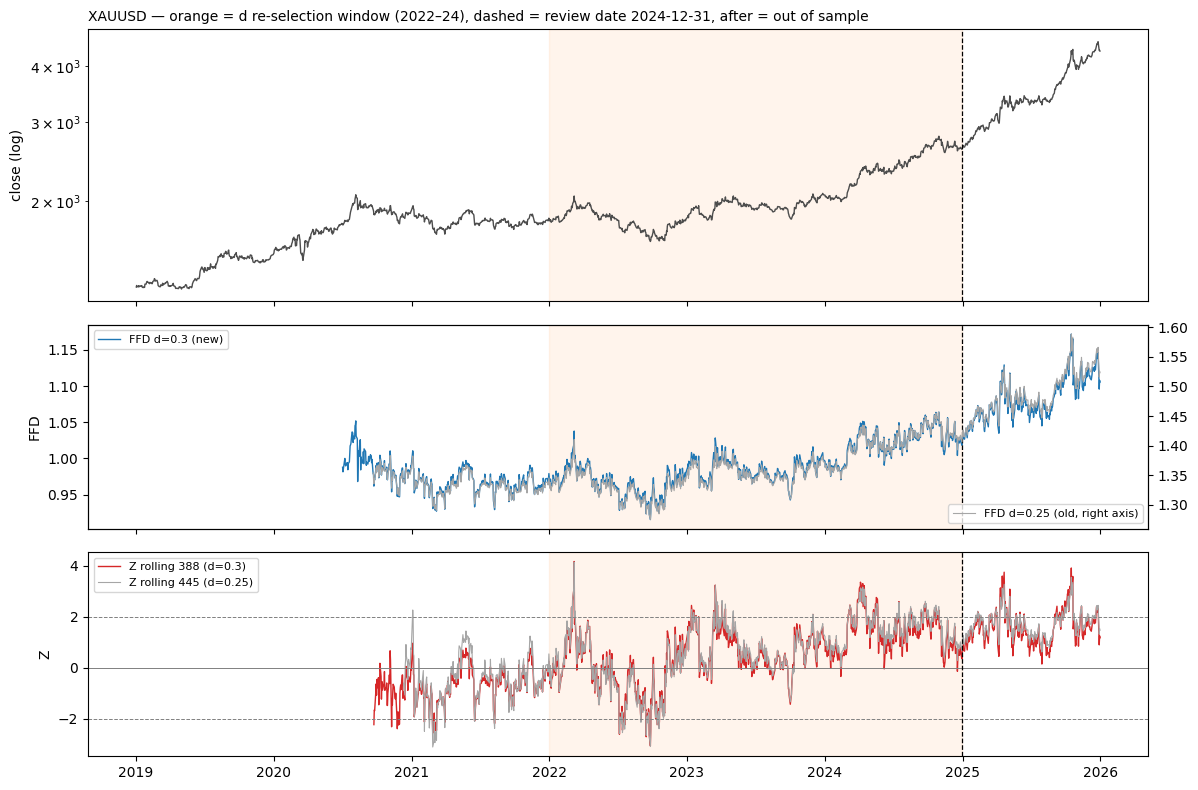

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1.5, 1.5]})
ax[0].plot(close.index, close, color='0.3', lw=1); ax[0].set_yscale('log'); ax[0].set_ylabel('close (log)')
ax[1].plot(f_new.index, f_new, color='tab:blue', lw=1, label=f'FFD d={D_NEW} (new)')
ax1b = ax[1].twinx(); ax1b.plot(f_old_full.index, f_old_full, color='0.65', lw=0.8, label=f'FFD d={D_OLD} (old, right axis)')
ax[1].legend(loc='upper left', fontsize=8); ax1b.legend(loc='lower right', fontsize=8); ax[1].set_ylabel('FFD')
ax[2].plot(z_new.index, z_new, color='tab:red', lw=1, label=f'Z rolling {W_NEW} (d={D_NEW})')
ax[2].plot(z_old.index, z_old, color='0.65', lw=0.8, label=f'Z rolling 445 (d={D_OLD})')
ax[2].legend(loc='upper left', fontsize=8); ax[2].set_ylabel('Z')
for lvl, ls in [(0, '-'), (2, '--'), (-2, '--')]:
    ax[2].axhline(lvl, color='0.5', lw=0.7, ls=ls)
for a in ax:
    a.axvspan(pd.Timestamp(SELECT[0]), pd.Timestamp(SELECT[1]), color='tab:orange', alpha=0.08)
    a.axvline(pd.Timestamp(REVIEW), color='k', lw=0.9, ls='--')
ax[0].set_title(f'{SYM} — orange = d re-selection window (2022–24), dashed = review date {REVIEW}, after = out of sample',
                loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## Step 4 — ADF: which period?

Re-selection uses **2022–2024 (the last 3 years)**, matching the original selection (train 2021–2023, also 3 years). The table also shows longer windows to explain why not "all history".

In [6]:
windows = {'2019/20 → 2024 (all available)': (None, '2024'),
           '2021–24': ('2021', '2024'), '2022–24 (selection)': ('2022', '2024'),
           '2024': ('2024', '2024'),
           '2025 (out of sample)': ('2025', '2025'), '2024–25 (partly out of sample)': ('2024', '2025')}
tab = pd.DataFrame({f'd={d}': {k: adf_p(f.loc[a:b]) for k, (a, b) in windows.items()}
                    for d, f in [(D_OLD, f_old_full), (D_NEW, f_new)]})
tab.round(4)

,d=0.25,d=0.3
2019/20 → 2024 (all available),0.0076,0.0001
2021–24,0.0168,0.0008
2022–24 (selection),0.0733,0.0092
2024,0.0670,0.0166
2025 (out of sample),0.0883,0.0228
2024–25 (partly out of sample),0.2637,0.0789


## How different is the new feature from the old one?

In [7]:
both = pd.DataFrame({'f_old': f_old_full, 'f_new': f_new, 'z_old': z_old, 'z_new': z_new}).dropna()
pd.DataFrame({p: {'corr FFD (0.25 vs 0.30)': both.loc[a:b, ['f_old', 'f_new']].corr().iloc[0, 1],
                  'corr Z (0.25 vs 0.30)': both.loc[a:b, ['z_old', 'z_new']].corr().iloc[0, 1],
                  'mean |Z diff|': (both.loc[a:b, 'z_new'] - both.loc[a:b, 'z_old']).abs().mean()}
              for p, (a, b) in {'2022–24': ('2022', '2024'), '2025': ('2025', '2025')}.items()}).round(3)

,2022–24,2025
corr FFD (0.25 vs 0.30),0.996,0.993
corr Z (0.25 vs 0.30),0.991,0.991
mean |Z diff|,0.153,0.185


### Reading

- **Why 2022–24, not all of 2019–2024.** Gold was range-bound for most of 2019–2023. A test over the whole history is dominated by those quiet years, so it passes even at d = 0.25 and wouldn't flag the 2024 rally. Re-selection needs to look at the regime the feature is in now. A fixed 3-year window does that, matches the original train length, and stays comparable from one review to the next.
- The new d only just passes on 2022–24 (p ≈ 0.009). The same "first d to pass sits on the threshold" fragility applies again.
- **Out of sample, d = 0.30 holds only partly.** 2025 alone passes at 5% but not 1% (p ≈ 0.023), and 2024–25 fails at 5% (p ≈ 0.079). The rally kept going, so the end-2025 review (data 2023–25) would ask for d ≈ 0.40. Raising d chases the trend one review late each time.
- **The new feature is nearly the same as the old one.** FFD and Z at d = 0.30 track d = 0.25 almost exactly (see the correlation table). The move from 0.25 to 0.30 fixes the ADF number but barely changes what the model would see.
- Every change also resets Z (new window, new anchor) and requires a retrain.